In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-05/PRJNA387475/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,ReleaseDate,create_date,version,Sample.Name,sample_type,SRA.Study,strain,Sample_Number,lat_lon,SAMPLE
,<chr>,<chr>,<int>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<chr>,<int>,⋯,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<int>
1,SRR5762049,AMPLICON,500,175193000,PRJNA387475,SAMN07257604,"Microbe\, viral or environmental",115788407,THE UNIVERSITY OF TEXAS AT AUSTIN,2014,⋯,2017-06-27T00:00:00Z,2017-06-27T16:33:00Z,1,15V2CcDNA_R1,Subgingival plaque (mixed culture),SRP110535,multiple,37,,NA
2,SRR5762050,AMPLICON,500,111967000,PRJNA387475,SAMN07257598,"Microbe\, viral or environmental",72415305,THE UNIVERSITY OF TEXAS AT AUSTIN,2014,⋯,2017-06-27T00:00:00Z,2017-06-27T16:33:00Z,1,13V2TcDNA_R1,Subgingival plaque (mixed culture),SRP110535,multiple,31,,NA
3,SRR5762051,AMPLICON,500,145687500,PRJNA387475,SAMN07257600,"Microbe\, viral or environmental",93229605,THE UNIVERSITY OF TEXAS AT AUSTIN,2014,⋯,2017-06-27T00:00:00Z,2017-06-27T16:33:00Z,1,14V2CcDNA_R1,Subgingival plaque (mixed culture),SRP110535,multiple,33,,NA
4,SRR5762052,AMPLICON,500,319587500,PRJNA387475,SAMN07257590,"Microbe\, viral or environmental",215429607,THE UNIVERSITY OF TEXAS AT AUSTIN,2014,⋯,2017-06-27T00:00:00Z,2017-06-27T16:33:00Z,1,6V2TcDNA_R1,Subgingival plaque (mixed culture),SRP110535,multiple,23,,NA
5,SRR5762053,AMPLICON,500,271601000,PRJNA387475,SAMN07257588,"Microbe\, viral or environmental",181136999,THE UNIVERSITY OF TEXAS AT AUSTIN,2014,⋯,2017-06-27T00:00:00Z,2017-06-27T16:33:00Z,1,6V2CcDNA_R1,Subgingival plaque (mixed culture),SRP110535,multiple,21,,NA
6,SRR5762054,AMPLICON,500,131772500,PRJNA387475,SAMN07257594,"Microbe\, viral or environmental",84059041,THE UNIVERSITY OF TEXAS AT AUSTIN,2014,⋯,2017-06-27T00:00:00Z,2017-06-27T16:32:00Z,1,11V2TcDNA_R1,Subgingival plaque (mixed culture),SRP110535,multiple,27,,NA


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "Experiment"                     "geo_loc_name_country"          
[17] "geo_loc_name_country_continent" "geo_loc_name"                  
[19] "HOST"                           "Instrument"                    
[21] "Library.Name"                   "LibraryLayout"                 
[23] "LibrarySelection"               "LibrarySource"                 
[25] "Organism"                       "Platform"                      
[27] "ReleaseDate"                    "create_date"                   
[29] "version"                        "Sample.Name"                   
[31] "sample_type"                    "SRA.Study"                     
[33] "strain"                         "Sample_Number"                 
[35] "lat_lon"                        "SAMPLE"

In [3]:
unique(initial_meta$'Assay.Type')

[1] "AMPLICON" "RNA-Seq"

In [4]:
#删除RNA-seq
initial_meta <- initial_meta[initial_meta$'Assay.Type' != 'RNA-Seq', ]

In [5]:
unique(initial_meta$'Assay.Type')

[1] "AMPLICON"

In [6]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = 'V4-V5',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = initial_meta$sample_type,
    public_time = initial_meta$ReleaseDate,
    PCR_primers = NA,
    title = "Microbiota and Metatranscriptome Changes Accompanying the Onset of Gingivitis",
    Disease_study = "YES",
    Status = NA,
    matched_samples = 'NO')

In [7]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 60
[1] 60


In [8]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>,<lgl>,<chr>
1,PRJNA387475,SRR5762049,15V2CcDNA_R1,NA,NA,NA,V4-V5,ILLUMINA,USA,Subgingival plaque (mixed culture),2017-06-27T00:00:00Z,NA,Microbiota and Metatranscriptome Changes Accompanying the Onset of Gingivitis,YES,NA,NO
2,PRJNA387475,SRR5762050,13V2TcDNA_R1,NA,NA,NA,V4-V5,ILLUMINA,USA,Subgingival plaque (mixed culture),2017-06-27T00:00:00Z,NA,Microbiota and Metatranscriptome Changes Accompanying the Onset of Gingivitis,YES,NA,NO
3,PRJNA387475,SRR5762051,14V2CcDNA_R1,NA,NA,NA,V4-V5,ILLUMINA,USA,Subgingival plaque (mixed culture),2017-06-27T00:00:00Z,NA,Microbiota and Metatranscriptome Changes Accompanying the Onset of Gingivitis,YES,NA,NO
4,PRJNA387475,SRR5762052,6V2TcDNA_R1,NA,NA,NA,V4-V5,ILLUMINA,USA,Subgingival plaque (mixed culture),2017-06-27T00:00:00Z,NA,Microbiota and Metatranscriptome Changes Accompanying the Onset of Gingivitis,YES,NA,NO
5,PRJNA387475,SRR5762053,6V2CcDNA_R1,NA,NA,NA,V4-V5,ILLUMINA,USA,Subgingival plaque (mixed culture),2017-06-27T00:00:00Z,NA,Microbiota and Metatranscriptome Changes Accompanying the Onset of Gingivitis,YES,NA,NO
6,PRJNA387475,SRR5762054,11V2TcDNA_R1,NA,NA,NA,V4-V5,ILLUMINA,USA,Subgingival plaque (mixed culture),2017-06-27T00:00:00Z,NA,Microbiota and Metatranscriptome Changes Accompanying the Onset of Gingivitis,YES,NA,NO


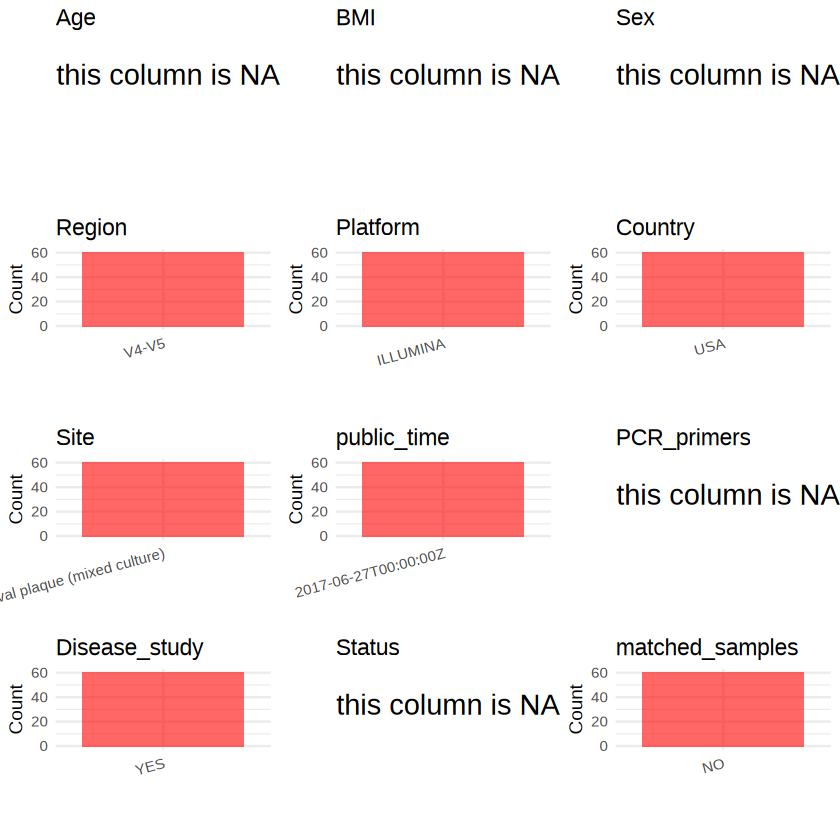

In [9]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [10]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-05/PRJNA387475/metadata.csv", quote = T)